In [16]:
import pandas as pd
import numpy as np


In [17]:
#1.

df=pd.read_csv('/content/winequality-red - winequality-red.csv')
df.shape

(1599, 12)

In [8]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [18]:

missing_counts = df.isnull().sum()
print("Missing values before replacement:\n", missing_counts)

# Fill missing values with the mean of each column
for col in df.columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mean())


print("\nMissing values after replacement:\n", df.isnull().sum())

Missing values before replacement:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Missing values after replacement:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [19]:
#2. Extracting 'alcohol' and 'citric acid' columns as vectors (NumPy arrays)
alcohol_vector = df['alcohol'].to_numpy()
citric_acid_vector = df['citric acid'].to_numpy()

print("Alcohol vector shape:", alcohol_vector.shape)
print("Citric acid vector shape:", citric_acid_vector.shape)
print("First 5 elements of alcohol vector:", alcohol_vector[:5])
print("First 5 elements of citric acid vector:", citric_acid_vector[:5])

Alcohol vector shape: (1599,)
Citric acid vector shape: (1599,)
First 5 elements of alcohol vector: [9.4 9.8 9.8 9.8 9.4]
First 5 elements of citric acid vector: [0.   0.   0.04 0.56 0.  ]


In [20]:
#3.  Select features: 'alcohol' and 'density'
selected_features = ['alcohol', 'density']
X = df[selected_features].to_numpy()

# Calculate the covariance matrix using np.cov(X.T)
covariance_matrix = np.cov(X.T)

print("Feature Matrix X shape:", X.shape)
print("\nCovariance Matrix:")
print(covariance_matrix)

Feature Matrix X shape: (1599, 2)

Covariance Matrix:
[[ 1.13564740e+00 -9.97951790e-04]
 [-9.97951790e-04  3.56202945e-06]]


In [21]:
#4. Perform eigen decomposition on the covariance matrix
eigenvalues, eigenvectors = np.linalg.eig(covariance_matrix)

# Since it's a 2x2 matrix, we'll sort them in descending order of eigenvalues
sorted_indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

print("Eigenvalues (sorted in descending order):")
for i, val in enumerate(eigenvalues):
    print(f"Eigenvalue {i+1}: {val:.8f}")

print("\nCorresponding Eigenvectors (as columns):")
for i in range(len(eigenvalues)):
    print(f"Eigenvector {i+1}: {eigenvectors[:, i]}")

Eigenvalues (sorted in descending order):
Eigenvalue 1: 1.13564827
Eigenvalue 2: 0.00000269

Corresponding Eigenvectors (as columns):
Eigenvector 1: [ 9.99999614e-01 -8.78753184e-04]
Eigenvector 2: [8.78753184e-04 9.99999614e-01]


Quality Score Distribution:
Quality 3: 10 samples (0.63%)
Quality 4: 53 samples (3.31%)
Quality 5: 681 samples (42.59%)
Quality 6: 638 samples (39.90%)
Quality 7: 199 samples (12.45%)
Quality 8: 18 samples (1.13%)

The most common wine quality score is: 5


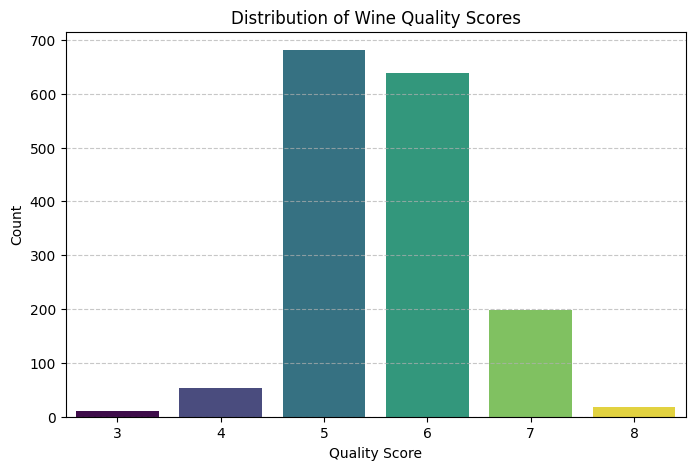

In [22]:
#5.
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each quality score
quality_counts = df['quality'].value_counts().sort_index()
quality_proportions = df['quality'].value_counts(normalize=True).sort_index() * 100

print("Quality Score Distribution:")
for q, count, prop in zip(quality_counts.index, quality_counts.values, quality_proportions.values):
    print(f"Quality {q}: {count} samples ({prop:.2f}%)")

most_common = quality_counts.idxmax()
print(f"\nThe most common wine quality score is: {most_common}")

# Plot the distribution
plt.figure(figsize=(8, 5))
sns.countplot(x='quality', data=df, palette='viridis', hue='quality', legend=False)
plt.title('Distribution of Wine Quality Scores')
plt.xlabel('Quality Score')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()